In [ ]:
!git clone https://github.com/gaia-solutions-on-demand/DFireDataset.git /content/D-Fire

fatal: destination path '/content/D-Fire' already exists and is not an empty directory.


In [ ]:
!du -sh /content/D-Fire

21M	/content/D-Fire


In [ ]:
!find /content/D-Fire -maxdepth 2 -type d

/content/D-Fire
/content/D-Fire/.git
/content/D-Fire/.git/hooks
/content/D-Fire/.git/refs
/content/D-Fire/.git/objects
/content/D-Fire/.git/logs
/content/D-Fire/.git/info
/content/D-Fire/.git/branches
/content/D-Fire/utils
/content/D-Fire/figures


In [ ]:
!du -sh /content/D-Fire

21M	/content/D-Fire


In [ ]:
!find /content/D-Fire -type f | head -30

/content/D-Fire/.git/description
/content/D-Fire/.git/hooks/pre-applypatch.sample
/content/D-Fire/.git/hooks/update.sample
/content/D-Fire/.git/hooks/fsmonitor-watchman.sample
/content/D-Fire/.git/hooks/pre-receive.sample
/content/D-Fire/.git/hooks/commit-msg.sample
/content/D-Fire/.git/hooks/pre-commit.sample
/content/D-Fire/.git/hooks/prepare-commit-msg.sample
/content/D-Fire/.git/hooks/push-to-checkout.sample
/content/D-Fire/.git/hooks/applypatch-msg.sample
/content/D-Fire/.git/hooks/post-update.sample
/content/D-Fire/.git/hooks/pre-rebase.sample
/content/D-Fire/.git/hooks/pre-merge-commit.sample
/content/D-Fire/.git/hooks/pre-push.sample
/content/D-Fire/.git/packed-refs
/content/D-Fire/.git/refs/heads/master
/content/D-Fire/.git/refs/remotes/origin/HEAD
/content/D-Fire/.git/HEAD
/content/D-Fire/.git/objects/pack/pack-0b3b4aca54d8374f4318cd0ec431635880738ec3.idx
/content/D-Fire/.git/objects/pack/pack-0b3b4aca54d8374f4318cd0ec431635880738ec3.pack
/content/D-Fire/.git/logs/refs/heads/

In [ ]:
!find /content/D-Fire -type f | wc -l

30


In [ ]:
!pip -q install kaggle

In [ ]:
!pip -q install kagglehub

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "sayedgamal99/smoke-fire-detection-yolo"
)

print("Dataset path:", path)

Using Colab cache for faster access to the 'smoke-fire-detection-yolo' dataset.
Dataset path: /kaggle/input/smoke-fire-detection-yolo


In [ ]:
import os

path = "/kaggle/input/smoke-fire-detection-yolo"

print("Path exists:", os.path.exists(path))
print("Contents:", os.listdir(path))

Path exists: True
Contents: ['data.yaml', 'data']


In [ ]:
import os

data_path = os.path.join(path, "data")

for item in os.listdir(data_path):
    print(item)

val
test
train


In [ ]:
print(open(os.path.join(path, "data.yaml")).read())

path: /kaggle/working/D Fire Dataset  # dataset root dir
train: data/train/images  # train images (relative to 'path')
val: data/val/images  # val images (relative to 'path')
test: data/test/images  # test images (relative to 'path')

# Classes
names: ['smoke', 'fire']  # Replace with your actual class names

# Counts
nc: 2  # number of classes
train_count: 14122
val_count: 3099
test_count: 4306



In [ ]:
import os

train_path = os.path.join(path, "data", "train")

for item in os.listdir(train_path):
    print(item)

labels
images


In [ ]:
import os

images_path = os.path.join(train_path, "images")
labels_path = os.path.join(train_path, "labels")

print("Images:", len(os.listdir(images_path)))
print("Labels:", len(os.listdir(labels_path)))

Images: 14122
Labels: 14122


In [ ]:
import os

image_files = os.listdir(images_path)
label_files = os.listdir(labels_path)

print("First image:", image_files[0])
print("First label:", label_files[0])

First image: WEB09284.jpg
First label: PublicDataset00021.txt


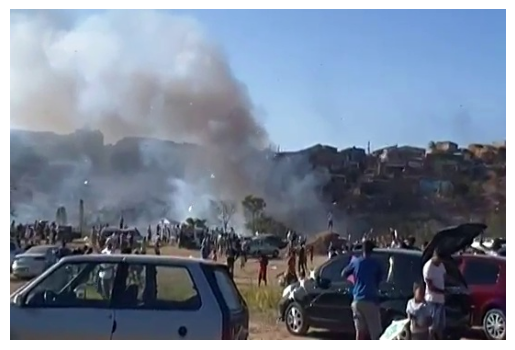

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_name = image_files[0]

image_path = os.path.join(images_path, image_name)

image = Image.open(image_path)

plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
label_name = os.path.splitext(image_name)[0] + ".txt"

print(label_name)

WEB09284.txt


In [ ]:
label_path = os.path.join(labels_path, label_name)

print(open(label_path).read())

0 0.3314814814814815 0.3611111111111111 0.5740740740740741 0.5666666666666667



In [ ]:
import os

image_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(images_path)
}

label_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(labels_path)
}

print("Images:", len(image_names))
print("Labels:", len(label_names))

Images: 14122
Labels: 14122


In [ ]:
missing_labels = image_names - label_names
missing_images = label_names - image_names

print("Images without labels:", len(missing_labels))
print("Labels without images:", len(missing_images))

Images without labels: 0
Labels without images: 0


In [ ]:
valid_classes = {0, 1}

for label_file in os.listdir(labels_path):
    label_path = os.path.join(labels_path, label_file)

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = line.strip().split()

        if len(values) != 5:
            print("Invalid format:", label_file)
            break

In [ ]:
for label_file in os.listdir(labels_path):
    label_path = os.path.join(labels_path, label_file)

    with open(label_path, "r") as f:
        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                continue

            x, y, width, height = map(float, values[1:])

            if not all(0 <= v <= 1 for v in [x, y, width, height]):
                print("Invalid values:", label_file, values)

In [ ]:
for label_file in os.listdir(labels_path):
    label_path = os.path.join(labels_path, label_file)

    with open(label_path, "r") as f:
        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            if class_id not in {0, 1}:
                print("Invalid class:", label_file, class_id)

In [ ]:
from PIL import Image
import os

image_name = "WEB08211.jpg"

image_path = os.path.join(images_path, image_name)
image = Image.open(image_path)

W, H = image.size

print("Width:", W)
print("Height:", H)

Width: 640
Height: 360


In [ ]:
x_center = 0.6336 * W
y_center = 0.3056 * H

box_width = 0.4984 * W
box_height = 0.45 * H

x1 = x_center - box_width / 2
y1 = y_center - box_height / 2

x2 = x_center + box_width / 2
y2 = y_center + box_height / 2

print("x1:", x1)
print("y1:", y1)
print("x2:", x2)
print("y2:", y2)

x1: 246.01600000000002
y1: 29.01599999999999
x2: 564.992
y2: 191.016


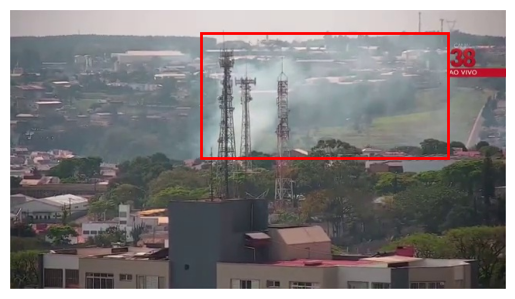

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots()

ax.imshow(image)

box = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(box)

ax.axis("off")
plt.show()

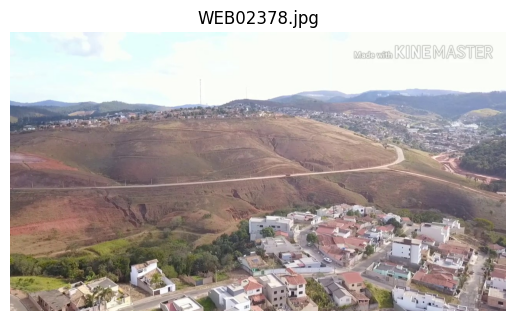

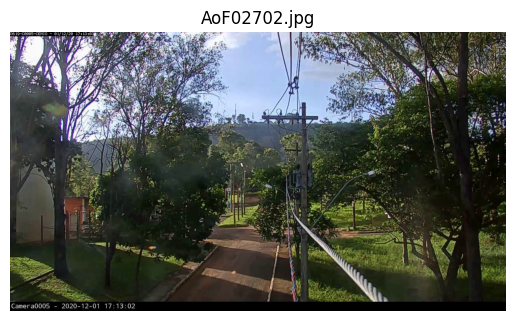

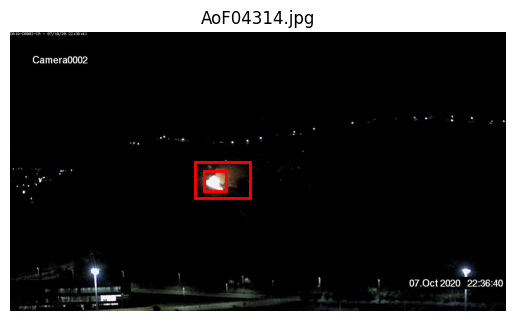

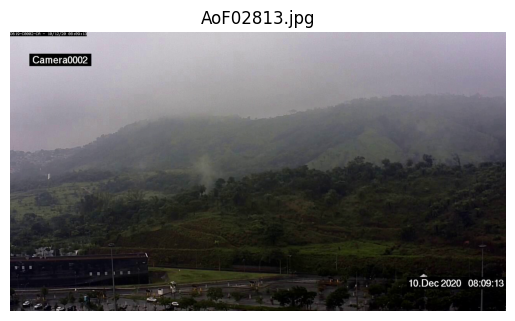

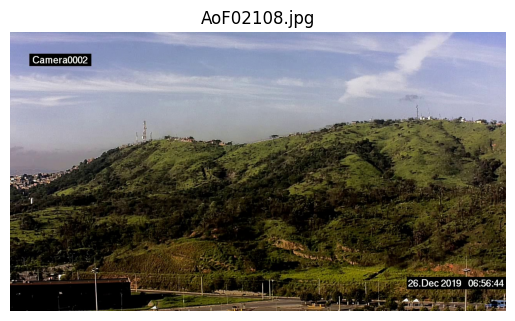

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os
from PIL import Image

random_images = random.sample(os.listdir(images_path), 5)

for image_name in random_images:

    image_path = os.path.join(images_path, image_name)
    label_name = os.path.splitext(image_name)[0] + ".txt"
    label_path = os.path.join(labels_path, label_name)

    image = Image.open(image_path)
    W, H = image.size

    fig, ax = plt.subplots()

    ax.imshow(image)

    with open(label_path, "r") as f:
        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])

            x_center = x * W
            y_center = y * H

            box_width = w * W
            box_height = h * H

            x1 = x_center - box_width / 2
            y1 = y_center - box_height / 2

            box = patches.Rectangle(
                (x1, y1),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(box)

    ax.set_title(image_name)
    ax.axis("off")
    plt.show()

In [ ]:
base_path = os.path.join(path, "data")

splits = ["train", "val", "test"]

for split in splits:
    images = os.path.join(base_path, split, "images")
    labels = os.path.join(base_path, split, "labels")

    print(split)
    print("Images:", len(os.listdir(images)))
    print("Labels:", len(os.listdir(labels)))
    print()

train
Images: 14122
Labels: 14122

val
Images: 3099
Labels: 3099

test
Images: 4306
Labels: 4306



In [ ]:
for split in splits:

    images_path = os.path.join(base_path, split, "images")
    labels_path = os.path.join(base_path, split, "labels")

    image_names = {
        os.path.splitext(f)[0]
        for f in os.listdir(images_path)
    }

    label_names = {
        os.path.splitext(f)[0]
        for f in os.listdir(labels_path)
    }

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    print(split)
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))
    print()

train
Images without labels: 0
Labels without images: 0

val
Images without labels: 0
Labels without images: 0

test
Images without labels: 0
Labels without images: 0



In [ ]:
print(path)

/kaggle/input/smoke-fire-detection-yolo


In [ ]:
!pip -q install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 4.8 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


In [ ]:
model = YOLO("yolo26n.pt")

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [ ]:
import shutil
from pathlib import Path

SOURCE = Path("/kaggle/input/smoke-fire-detection-yolo")
DEST = Path("/content/D-Fire")

# حذف النسخة الناقصة فقط
if DEST.exists():
    shutil.rmtree(DEST)
    print("Old incomplete copy removed.")

# نسخ Dataset كامل
shutil.copytree(SOURCE, DEST)

print("\nDataset copied successfully.")
print("Destination:", DEST)

# عرض المحتويات
print("\nContents:")
for item in DEST.iterdir():
    print(" -", item.name)

Old incomplete copy removed.

Dataset copied successfully.
Destination: /content/D-Fire

Contents:
 - data.yaml
 - data


In [ ]:
from pathlib import Path

yaml_path = Path("/content/D-Fire/data.yaml")

print(yaml_path.read_text(encoding="utf-8"))

path: /kaggle/working/D Fire Dataset  # dataset root dir
train: data/train/images  # train images (relative to 'path')
val: data/val/images  # val images (relative to 'path')
test: data/test/images  # test images (relative to 'path')

# Classes
names: ['smoke', 'fire']  # Replace with your actual class names

# Counts
nc: 2  # number of classes
train_count: 14122
val_count: 3099
test_count: 4306



In [ ]:
yaml_path = "/content/D-Fire/data.yaml"

yaml_content = """
path: /content/D-Fire
train: data/train/images
val: data/val/images
test: data/test/images

names:
  0: smoke
  1: fire

nc: 2
"""

with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("data.yaml updated successfully!\n")
print(open(yaml_path, encoding="utf-8").read())

data.yaml updated successfully!


path: /content/D-Fire
train: data/train/images
val: data/val/images
test: data/test/images

names:
  0: smoke
  1: fire

nc: 2



In [ ]:
from pathlib import Path
from PIL import Image
from collections import Counter

ROOT = Path("/content/D-Fire/data")

splits = ["train", "val", "test"]
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_images = 0
total_labels = 0
total_objects = 0

bad_pairs = []
bad_format = []
bad_class = []
bad_coordinates = []
bad_images = []

class_counter = Counter()
background_counter = Counter()


for split in splits:

    images_dir = ROOT / split / "images"
    labels_dir = ROOT / split / "labels"

    images = [
        f for f in images_dir.iterdir()
        if f.is_file() and f.suffix.lower() in extensions
    ]

    labels = list(labels_dir.glob("*.txt"))

    image_names = {f.stem for f in images}
    label_names = {f.stem for f in labels}

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    total_images += len(images)
    total_labels += len(labels)

    print("=" * 70)
    print(split.upper())
    print("=" * 70)

    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))

    if missing_labels:
        bad_pairs.extend(
            [(split, x, "missing label") for x in missing_labels]
        )

    if missing_images:
        bad_pairs.extend(
            [(split, x, "missing image") for x in missing_images]
        )

    # --------------------------------------------------------
    # Check labels
    # --------------------------------------------------------

    split_objects = 0
    split_background = 0

    for label_file in labels:

        text = label_file.read_text(
            encoding="utf-8",
            errors="ignore"
        ).strip()

        # Empty label = background image
        if not text:
            split_background += 1
            continue

        for line_no, line in enumerate(text.splitlines(), 1):

            parts = line.split()

            if len(parts) != 5:
                bad_format.append(
                    (split, label_file.name, line_no, line)
                )
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

            except ValueError:
                bad_format.append(
                    (split, label_file.name, line_no, line)
                )
                continue

            split_objects += 1
            total_objects += 1

            # Class ID
            if class_id not in [0, 1]:
                bad_class.append(
                    (split, label_file.name, line_no, class_id)
                )
            else:
                class_counter[class_id] += 1

            # Coordinates
            coords = [x, y, w, h]

            if any(v < 0 or v > 1 for v in coords):
                bad_coordinates.append(
                    (split, label_file.name, line_no, coords)
                )

    background_counter[split] = split_background

    print("Objects:", split_objects)
    print("Background images:", split_background)

    # --------------------------------------------------------
    # Check images
    # --------------------------------------------------------

    for image_file in images:

        try:
            with Image.open(image_file) as img:
                img.verify()

            with Image.open(image_file) as img:
                img.load()

        except Exception as e:
            bad_images.append(
                (split, image_file.name, str(e))
            )


# ============================================================
# FINAL REPORT
# ============================================================

print("\n")
print("=" * 70)
print("FINAL DATASET REPORT")
print("=" * 70)

print(f"Total images       : {total_images}")
print(f"Total labels       : {total_labels}")
print(f"Total objects      : {total_objects}")

print("\nClass distribution:")
print("Smoke (0):", class_counter[0])
print("Fire  (1):", class_counter[1])

print("\nBackground images:")
for split in splits:
    print(f"{split}: {background_counter[split]}")

print("\nProblems found:")
print("Image/label pairing :", len(bad_pairs))
print("Invalid label format:", len(bad_format))
print("Invalid class IDs   :", len(bad_class))
print("Invalid coordinates :", len(bad_coordinates))
print("Corrupt images      :", len(bad_images))

print("\n" + "=" * 70)

if not any([
    bad_pairs,
    bad_format,
    bad_class,
    bad_coordinates,
    bad_images
]):
    print("STATUS: DATASET PASSED FULL VALIDATION")
else:
    print("STATUS: PROBLEMS FOUND")

print("=" * 70)

TRAIN
Images: 14122
Labels: 14122
Images without labels: 0
Labels without images: 0
Objects: 17432
Background images: 6458
VAL
Images: 3099
Labels: 3099
Images without labels: 0
Labels without images: 0
Objects: 3932
Background images: 1375
TEST
Images: 4298
Labels: 4298
Images without labels: 0
Labels without images: 0
Objects: 5176
Background images: 2005


FINAL DATASET REPORT
Total images       : 21519
Total labels       : 21519
Total objects      : 26540

Class distribution:
Smoke (0): 11857
Fire  (1): 14683

Background images:
train: 6458
val: 1375
test: 2005

Problems found:
Image/label pairing : 0
Invalid label format: 0
Invalid class IDs   : 0
Invalid coordinates : 0
Corrupt images      : 0

STATUS: DATASET PASSED FULL VALIDATION


In [ ]:
print("=" * 70)
print("THE 8 INVALID COORDINATES")
print("=" * 70)

for item in bad_coordinates:
    print(item)

THE 8 INVALID COORDINATES
('test', 'WEB10770.txt', 2, [0.50703125, 0.3625, 1.0078125, 0.7138888888888889])
('test', 'WEB11606.txt', 1, [0.2578125, 0.4986111111111111, 0.50625, 1.0027777777777778])
('test', 'WEB10821.txt', 3, [0.49843750000000003, 0.3388888888888889, 1.0093750000000001, 0.6166666666666667])
('test', 'WEB11600.txt', 1, [0.496875, 0.4222222222222222, 1.0562500000000001, 0.8388888888888889])
('test', 'WEB10775.txt', 3, [0.496875, 0.27083333333333337, 1.015625, 0.5750000000000001])
('test', 'WEB11090.txt', 1, [0.5437500000000001, 0.5013888888888889, 0.5375, 1.0027777777777778])
('test', 'WEB10769.txt', 2, [0.50546875, 0.3625, 1.0296875, 0.7083333333333334])
('test', 'WEB11598.txt', 1, [0.49921875000000004, 0.4013888888888889, 1.0359375, 0.8138888888888889])


In [ ]:
from pathlib import Path

images_dir = Path("/content/D-Fire/data/test/images")
labels_dir = Path("/content/D-Fire/data/test/labels")

bad_labels = [
    "WEB10770.txt",
    "WEB11606.txt",
    "WEB10821.txt",
    "WEB11600.txt",
    "WEB10775.txt",
    "WEB11090.txt",
    "WEB10769.txt",
    "WEB11598.txt"
]

image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

for label_name in bad_labels:

    # حذف الـlabel
    label_path = labels_dir / label_name

    if label_path.exists():
        label_path.unlink()
        print("Deleted label:", label_name)

    # البحث عن الصورة المطابقة
    stem = Path(label_name).stem

    for ext in image_extensions:

        image_path = images_dir / f"{stem}{ext}"

        if image_path.exists():
            image_path.unlink()
            print("Deleted image:", image_path.name)
            break

print("\nDone.")

Deleted label: WEB10770.txt
Deleted image: WEB10770.jpg
Deleted label: WEB11606.txt
Deleted image: WEB11606.jpg
Deleted label: WEB10821.txt
Deleted image: WEB10821.jpg
Deleted label: WEB11600.txt
Deleted image: WEB11600.jpg
Deleted label: WEB10775.txt
Deleted image: WEB10775.jpg
Deleted label: WEB11090.txt
Deleted image: WEB11090.jpg
Deleted label: WEB10769.txt
Deleted image: WEB10769.jpg
Deleted label: WEB11598.txt
Deleted image: WEB11598.jpg

Done.


In [ ]:
from ultralytics import YOLO

# تحميل النموذج pretrained
model = YOLO("yolo26n.pt")

# التدريب النهائي
results = model.train(
    data="/content/D-Fire/data.yaml",
    epochs=30,
    imgsz=640,
    batch=48,
    device=0,
    workers=2,
    patience=10,
    project="/content/runs",
    name="fire_smoke_final"
)

Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=48, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/D-Fire/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fire_smoke_final, nbs=64, nms=None, opset=None, op

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/fire_smoke_final/weights/best.pt")

test_results = model.val(
    data="/content/D-Fire/data.yaml",
    split="test",
    imgsz=640,
    batch=48,
    device=0
)

Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,226 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 12.2±9.9 MB/s, size: 44.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/D-Fire/data/test/labels... 4298 images, 2005 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4298/4298 555.3it/s 7.7s
val: /content/D-Fire/data/test/images/WEB11243.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/data/test/images/WEB11244.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/data/test/images/WEB11245.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/data/test/images/WEB11313.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/data/test/images/WEB11315.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/data/test/images/WEB11

In [ ]:
# ============================================================
# FIRE / SMOKE MODEL - FULL ERROR AUDIT
# ============================================================

from ultralytics import YOLO
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import cv2
import os

# ------------------------------------------------------------
# 1) PATHS
# ------------------------------------------------------------

DATASET = Path("/content/D-Fire")
TEST_IMAGES = DATASET / "data/test/images"
TEST_LABELS = DATASET / "data/test/labels"

MODEL_PATH = "/content/runs/fire_smoke_final/weights/best.pt"

# YOLO model
model = YOLO(MODEL_PATH)

print("Model loaded successfully:")
print(MODEL_PATH)


# ------------------------------------------------------------
# 2) BASIC DATASET AUDIT
# ------------------------------------------------------------

image_files = sorted(
    list(TEST_IMAGES.glob("*.jpg")) +
    list(TEST_IMAGES.glob("*.jpeg")) +
    list(TEST_IMAGES.glob("*.png"))
)

label_files = sorted(TEST_LABELS.glob("*.txt"))

print("\n" + "="*70)
print("1) DATASET SIZE")
print("="*70)

print("Test images :", len(image_files))
print("Test labels :", len(label_files))


# ------------------------------------------------------------
# 3) IMAGE <-> LABEL PAIRING
# ------------------------------------------------------------

image_names = {p.stem for p in image_files}
label_names = {p.stem for p in label_files}

missing_labels = sorted(image_names - label_names)
orphan_labels = sorted(label_names - image_names)

print("\n" + "="*70)
print("2) IMAGE / LABEL PAIRING")
print("="*70)

print("Images without labels :", len(missing_labels))
print("Labels without images :", len(orphan_labels))

if missing_labels:
    print("Examples:", missing_labels[:10])

if orphan_labels:
    print("Examples:", orphan_labels[:10])


# ------------------------------------------------------------
# 4) ANNOTATION AUDIT
# ------------------------------------------------------------

class_counter = Counter()

invalid_format = []
invalid_class = []
invalid_coordinates = []
empty_labels = []

box_sizes = []
object_per_image = []

for img_path in image_files:

    label_path = TEST_LABELS / f"{img_path.stem}.txt"

    if not label_path.exists():
        continue

    with open(label_path, "r") as f:
        lines = [x.strip() for x in f.readlines() if x.strip()]

    if len(lines) == 0:
        empty_labels.append(img_path.name)
        object_per_image.append(0)
        continue

    object_per_image.append(len(lines))

    for line_no, line in enumerate(lines, start=1):

        parts = line.split()

        if len(parts) != 5:
            invalid_format.append(
                (img_path.name, line_no, line)
            )
            continue

        cls, xc, yc, w, h = map(float, parts)

        if cls not in [0, 1]:
            invalid_class.append(
                (img_path.name, line_no, cls)
            )
            continue

        if not (
            0 <= xc <= 1 and
            0 <= yc <= 1 and
            0 < w <= 1 and
            0 < h <= 1
        ):
            invalid_coordinates.append(
                (img_path.name, line_no, xc, yc, w, h)
            )
            continue

        class_counter[int(cls)] += 1

        box_sizes.append({
            "image": img_path.name,
            "class": int(cls),
            "width": w,
            "height": h,
            "area": w * h
        })


print("\n" + "="*70)
print("3) ANNOTATION QUALITY")
print("="*70)

print("Empty/background images :", len(empty_labels))
print("Invalid format          :", len(invalid_format))
print("Invalid class IDs       :", len(invalid_class))
print("Invalid coordinates     :", len(invalid_coordinates))

print("\nObjects:")
print("Smoke:", class_counter[0])
print("Fire :", class_counter[1])


# ------------------------------------------------------------
# 5) OBJECT SIZE ANALYSIS
# ------------------------------------------------------------

boxes_df = pd.DataFrame(box_sizes)

print("\n" + "="*70)
print("4) BOUNDING BOX SIZE ANALYSIS")
print("="*70)

if len(boxes_df):

    for cls_id, cls_name in [(0, "Smoke"), (1, "Fire")]:

        subset = boxes_df[boxes_df["class"] == cls_id]

        print(f"\n{cls_name}")

        print("Objects:", len(subset))

        print(
            "Average area :",
            round(subset["area"].mean(), 5)
        )

        print(
            "Minimum area :",
            round(subset["area"].min(), 5)
        )

        print(
            "Median area  :",
            round(subset["area"].median(), 5)
        )

        print(
            "Small boxes (<1% image):",
            int((subset["area"] < 0.01).sum())
        )

        print(
            "Very small (<0.25% image):",
            int((subset["area"] < 0.0025).sum())
        )


# ------------------------------------------------------------
# 6) OBJECT COUNT PER IMAGE
# ------------------------------------------------------------

print("\n" + "="*70)
print("5) OBJECT COUNT PER IMAGE")
print("="*70)

object_counts = Counter(object_per_image)

for n, count in sorted(object_counts.items()):
    print(f"{n:3} objects -> {count} images")


# ------------------------------------------------------------
# 7) FIRE / SMOKE CO-OCCURRENCE
# ------------------------------------------------------------

fire_only = []
smoke_only = []
both = []
background = []

for img_path in image_files:

    label_path = TEST_LABELS / f"{img_path.stem}.txt"

    if not label_path.exists():
        continue

    classes = set()

    with open(label_path) as f:
        for line in f:

            parts = line.split()

            if len(parts) == 5:
                classes.add(int(float(parts[0])))

    if not classes:
        background.append(img_path.name)

    elif classes == {0}:
        smoke_only.append(img_path.name)

    elif classes == {1}:
        fire_only.append(img_path.name)

    elif classes == {0, 1}:
        both.append(img_path.name)


print("\n" + "="*70)
print("6) FIRE / SMOKE DISTRIBUTION")
print("="*70)

print("Background only :", len(background))
print("Smoke only      :", len(smoke_only))
print("Fire only       :", len(fire_only))
print("Fire + Smoke    :", len(both))


# ------------------------------------------------------------
# 8) YOLO TEST EVALUATION
# ------------------------------------------------------------

print("\n" + "="*70)
print("7) YOLO TEST EVALUATION")
print("="*70)

results = model.val(
    data=str(DATASET / "data.yaml"),
    split="test",
    imgsz=640,
    batch=48,
    device=0,
    plots=True,
    save_json=True
)

print("\nEvaluation completed.")


# ------------------------------------------------------------
# 9) SAVE DATA AUDIT
# ------------------------------------------------------------

audit_path = "/content/test_annotation_audit.csv"

if len(boxes_df):
    boxes_df.to_csv(audit_path, index=False)

print("\n" + "="*70)
print("8) AUDIT FILE")
print("="*70)

print("Saved:", audit_path)


# ------------------------------------------------------------
# 10) FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*70)
print("FINAL AUDIT SUMMARY")
print("="*70)

print("Test images              :", len(image_files))
print("Test labels              :", len(label_files))
print("Missing labels           :", len(missing_labels))
print("Orphan labels            :", len(orphan_labels))
print("Background images        :", len(background))
print("Smoke objects            :", class_counter[0])
print("Fire objects             :", class_counter[1])
print("Invalid annotations      :", (
    len(invalid_format) +
    len(invalid_class) +
    len(invalid_coordinates)
))

print("\nAudit finished.")

Model loaded successfully:
/content/runs/fire_smoke_final/weights/best.pt

1) DATASET SIZE
Test images : 4298
Test labels : 4298

2) IMAGE / LABEL PAIRING
Images without labels : 0
Labels without images : 0

3) ANNOTATION QUALITY
Empty/background images : 2005
Invalid format          : 0
Invalid class IDs       : 0
Invalid coordinates     : 4

Objects:
Smoke: 2303
Fire : 2869

4) BOUNDING BOX SIZE ANALYSIS

Smoke
Objects: 2303
Average area : 0.22509
Minimum area : 4e-05
Median area  : 0.14169
Small boxes (<1% image): 495
Very small (<0.25% image): 208

Fire
Objects: 2869
Average area : 0.02407
Minimum area : 4e-05
Median area  : 0.0053
Small boxes (<1% image): 1858
Very small (<0.25% image): 970

5) OBJECT COUNT PER IMAGE
  0 objects -> 2005 images
  1 objects -> 1219 images
  2 objects -> 419 images
  3 objects -> 211 images
  4 objects -> 153 images
  5 objects -> 118 images
  6 objects -> 78 images
  7 objects -> 46 images
  8 objects -> 12 images
  9 objects -> 13 images
 10 object

In [ ]:
from google.colab import drive
import shutil
import os

drive.mount('/content/drive')

src = "/content/runs/fire_smoke_final/weights/best.pt"
dst = "/content/drive/MyDrive/fire_smoke_best.pt"

shutil.copy2(src, dst)

print("Best weight saved successfully.")
print("Path:", dst)
print("Size:", round(os.path.getsize(dst) / (1024 * 1024), 2), "MB")

Mounted at /content/drive
Best weight saved successfully.
Path: /content/drive/MyDrive/fire_smoke_best.pt
Size: 5.11 MB


In [ ]:
import os
import glob
import numpy as np
from collections import defaultdict

ROOT = "/content/D-Fire/data"

splits = ["train", "val", "test"]

for split in splits:

    label_dir = f"{ROOT}/{split}/labels"

    fire_areas = []

    for label_file in glob.glob(os.path.join(label_dir, "*.txt")):

        with open(label_file, "r") as f:
            for line in f:

                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                cls, x, y, w, h = map(float, parts)

                # 1 = Fire
                if int(cls) == 1:

                    area = w * h
                    fire_areas.append(area)

    fire_areas = np.array(fire_areas)

    print("\n" + "="*50)
    print(split.upper())
    print("="*50)

    print("Fire objects:", len(fire_areas))

    print("Average area :", fire_areas.mean())
    print("Median area  :", np.median(fire_areas))

    print("< 1% image   :", np.sum(fire_areas < 0.01))
    print("< 0.25% image:", np.sum(fire_areas < 0.0025))

    print("< 1% %       :", np.mean(fire_areas < 0.01) * 100)
    print("< 0.25% %    :", np.mean(fire_areas < 0.0025) * 100)


TRAIN
Fire objects: 9638
Average area : 0.02465382775500452
Median area  : 0.005419988037771002
< 1% image   : 6209
< 0.25% image: 3222
< 1% %       : 64.422079269558
< 0.25% %    : 33.4301722349035

VAL
Fire objects: 2176
Average area : 0.023683548835188573
Median area  : 0.005261230468750001
< 1% image   : 1392
< 0.25% image: 699
< 1% %       : 63.970588235294116
< 0.25% %    : 32.123161764705884

TEST
Fire objects: 2869
Average area : 0.02406895267076799
Median area  : 0.00529513888888889
< 1% image   : 1858
< 0.25% image: 970
< 1% %       : 64.76124085047054
< 0.25% %    : 33.80968978738236


In [ ]:
from ultralytics import YOLO
from PIL import Image, ImageDraw
import pandas as pd
import os
import math

# ==============================
# 1) Load model + FN results
# ==============================

model = YOLO("/content/runs/fire_smoke_final/weights/best.pt")

df_fn = pd.read_csv("/content/fire_false_negatives.csv")

IMG_DIR = "/content/D-Fire/data/test/images"
LABEL_DIR = "/content/D-Fire/data/test/labels"

# أصغر 20 حريق فشل النموذج في اكتشافه
samples = df_fn.sort_values("fire_area").head(20)


# ==============================
# 2) IoU
# ==============================

def iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - inter

    return inter / union if union > 0 else 0


# ==============================
# 3) Create visualizations
# ==============================

output_dir = "/content/fire_fn_visuals"
os.makedirs(output_dir, exist_ok=True)


for _, row in samples.iterrows():

    image_name = row["image"]

    image_path = os.path.join(
        IMG_DIR,
        image_name
    )

    label_path = os.path.join(
        LABEL_DIR,
        os.path.splitext(image_name)[0] + ".txt"
    )

    image = Image.open(image_path).convert("RGB")

    img_w, img_h = image.size

    draw = ImageDraw.Draw(image)

    # --------------------------
    # Ground Truth Fire boxes
    # --------------------------

    gt_boxes = []

    with open(label_path, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, w, h = map(float, parts)

            if int(cls) != 1:
                continue

            x1 = (xc - w/2) * img_w
            y1 = (yc - h/2) * img_h

            x2 = (xc + w/2) * img_w
            y2 = (yc + h/2) * img_h

            gt_boxes.append([x1, y1, x2, y2])

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="green",
                width=4
            )

            draw.text(
                (x1, max(0, y1-15)),
                "GT FIRE",
                fill="green"
            )


    # --------------------------
    # Model predictions
    # --------------------------

    result = model.predict(
        image_path,
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    best_iou = 0
    best_pred = None

    for box, cls, conf in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.cls.cpu().numpy(),
        result.boxes.conf.cpu().numpy()
    ):

        if int(cls) != 1:
            continue

        box = box.tolist()

        current_iou = max(
            [iou(box, gt) for gt in gt_boxes],
            default=0
        )

        if current_iou > best_iou:

            best_iou = current_iou

            best_pred = {
                "box": box,
                "conf": float(conf)
            }


    # --------------------------
    # Draw prediction
    # --------------------------

    if best_pred:

        box = best_pred["box"]

        draw.rectangle(
            box,
            outline="red",
            width=4
        )

        draw.text(
            (box[0], box[1]),
            f"Pred Fire {best_pred['conf']:.2f} | IoU {best_iou:.2f}",
            fill="red"
        )

    else:

        draw.text(
            (10, 10),
            "NO FIRE PREDICTION",
            fill="red"
        )


    # --------------------------
    # Save
    # --------------------------

    save_path = os.path.join(
        output_dir,
        image_name
    )

    image.save(save_path)


print("=" * 60)
print("VISUAL INSPECTION READY")
print("=" * 60)
print("Images saved:", len(samples))
print("Folder:", output_dir)

VISUAL INSPECTION READY
Images saved: 20
Folder: /content/fire_fn_visuals


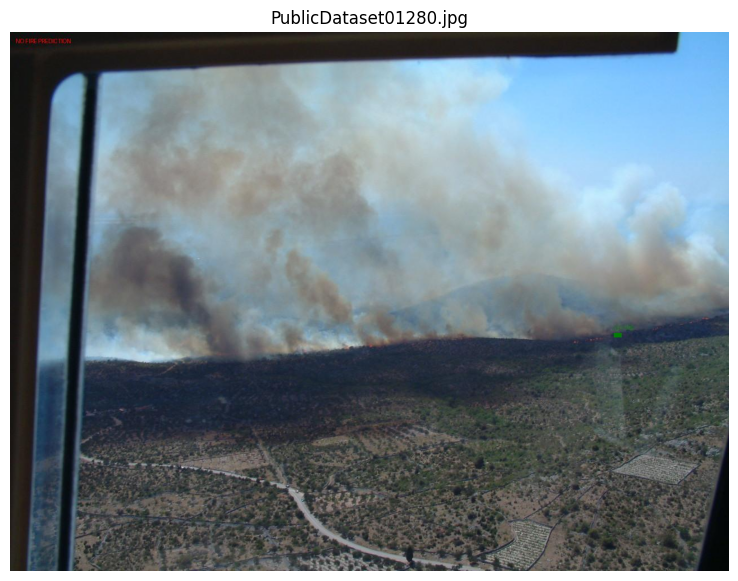

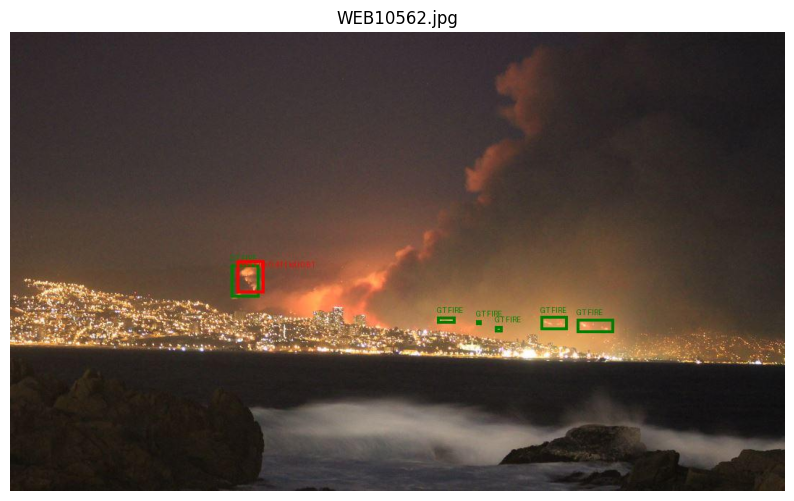

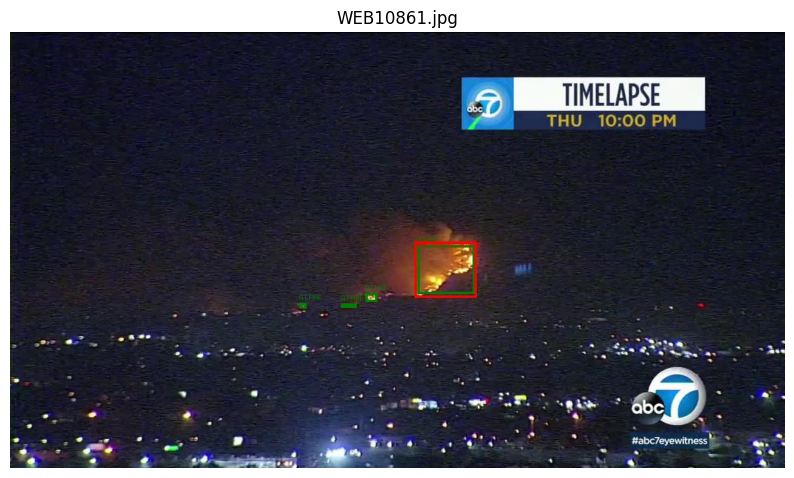

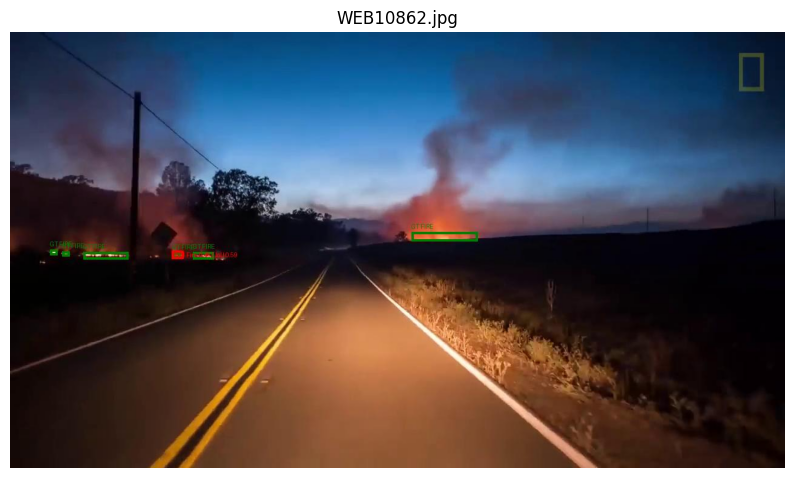

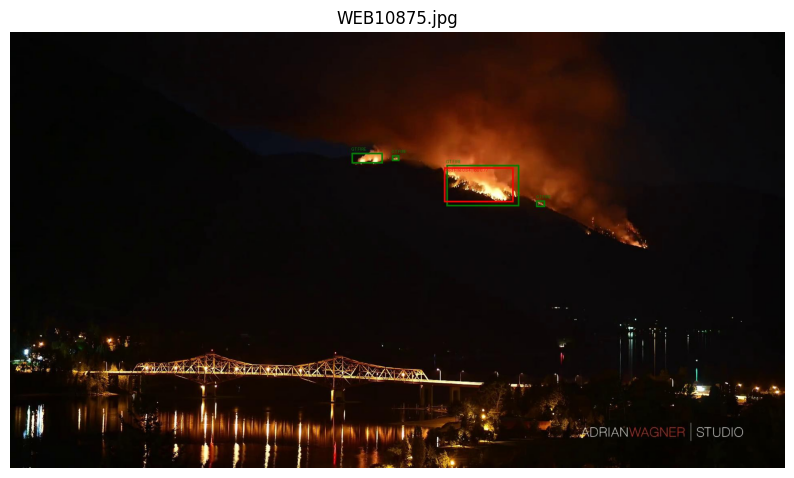

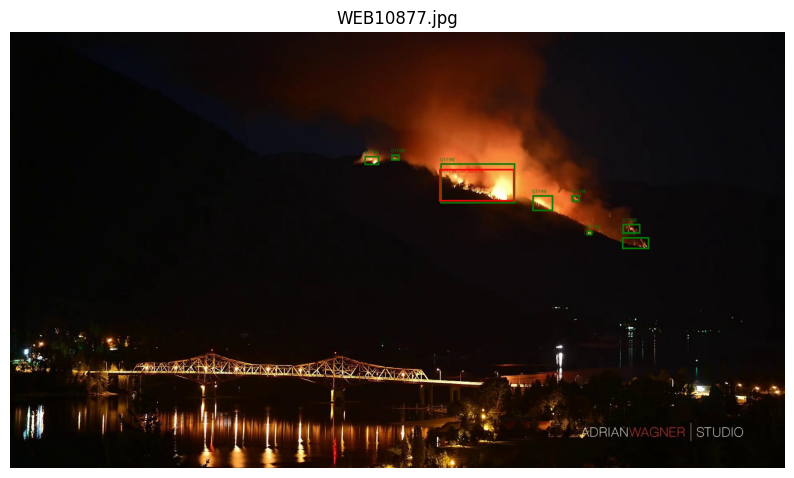

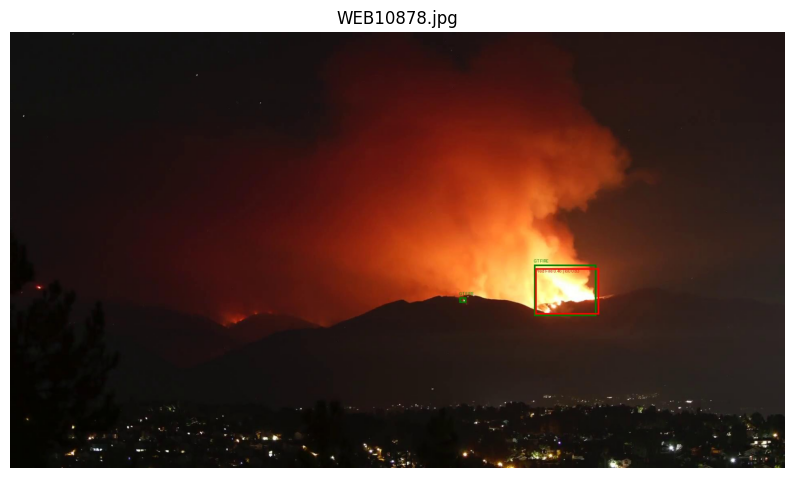

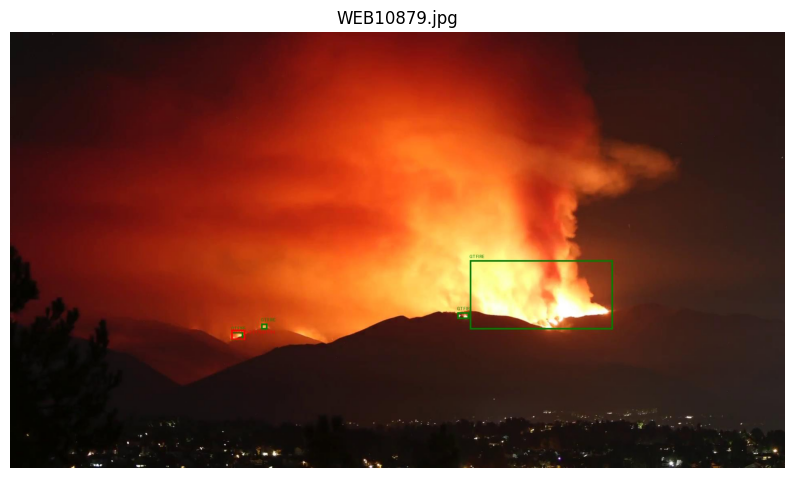

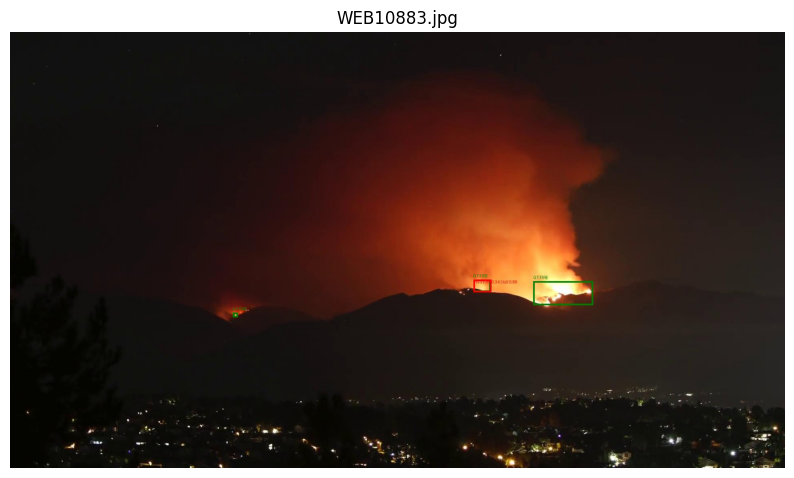

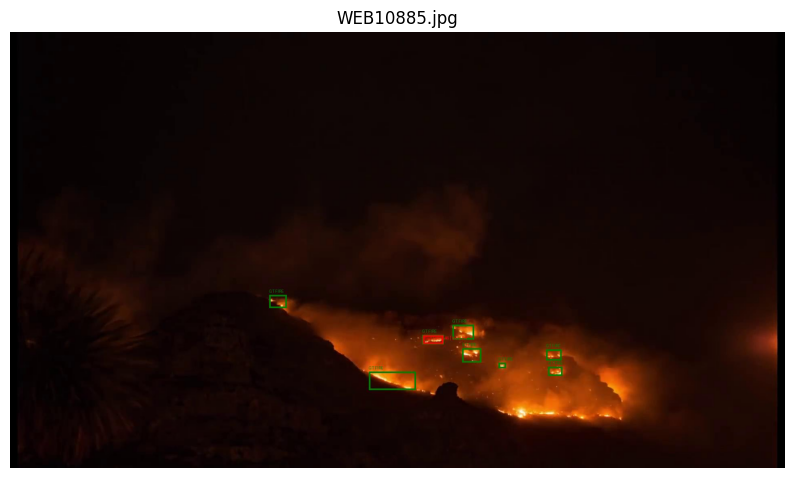

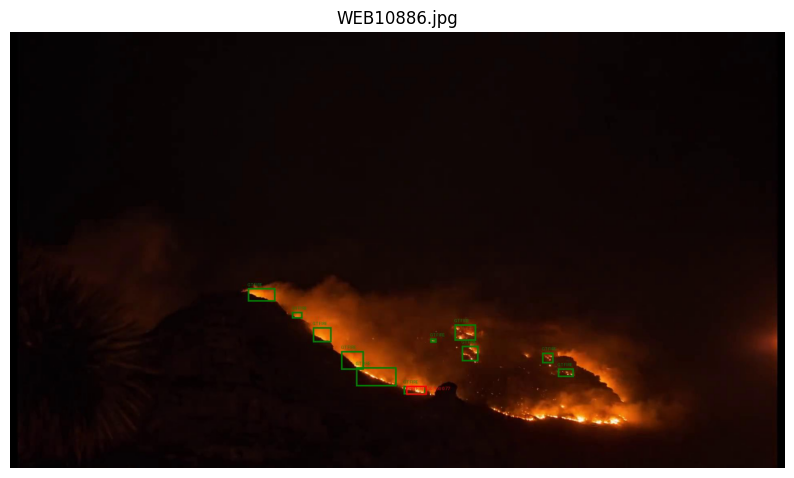

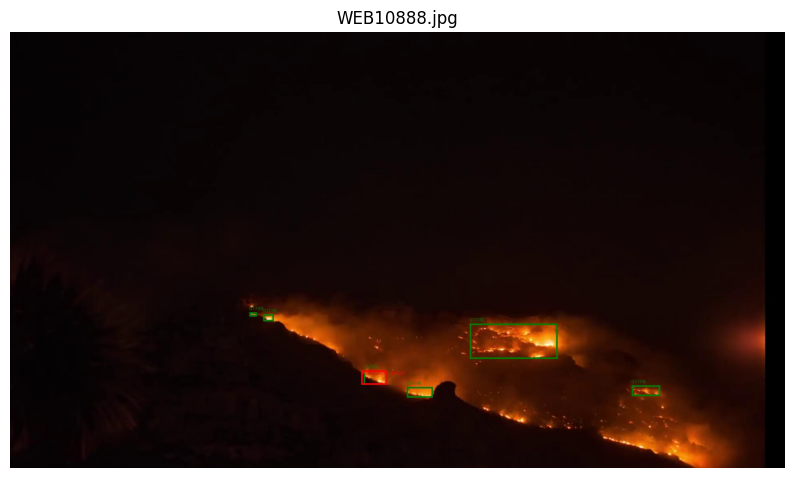

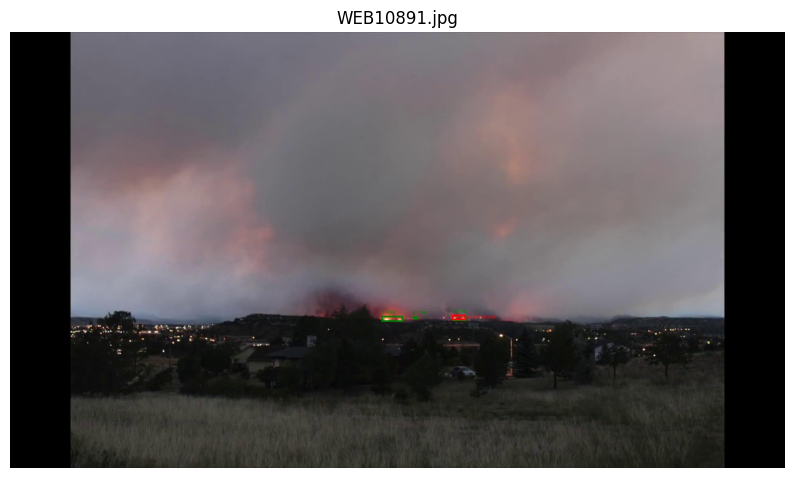

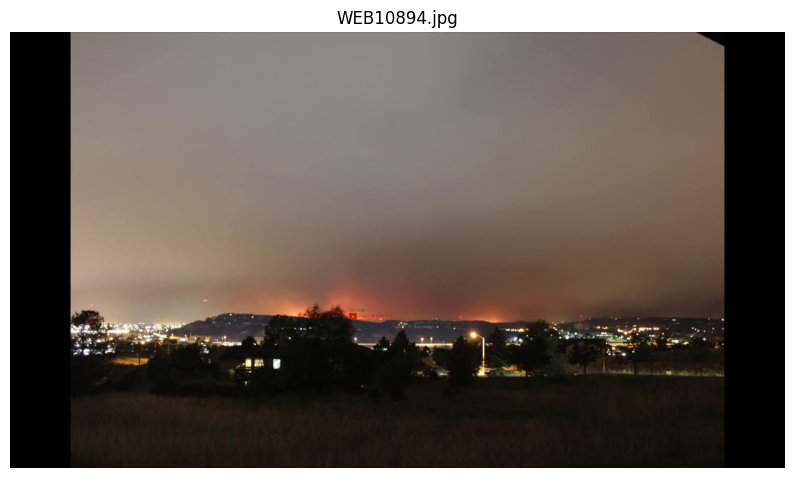

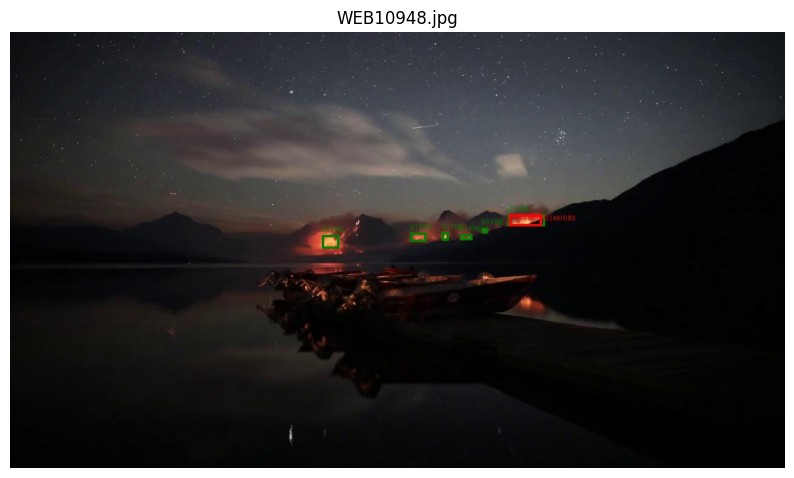

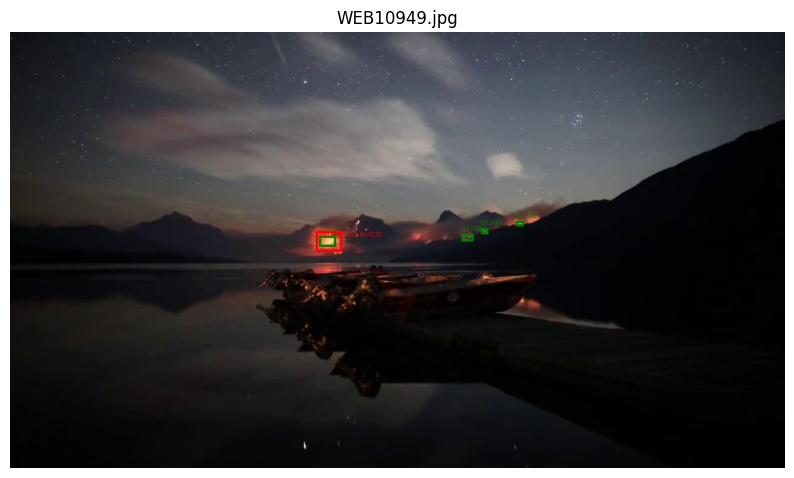

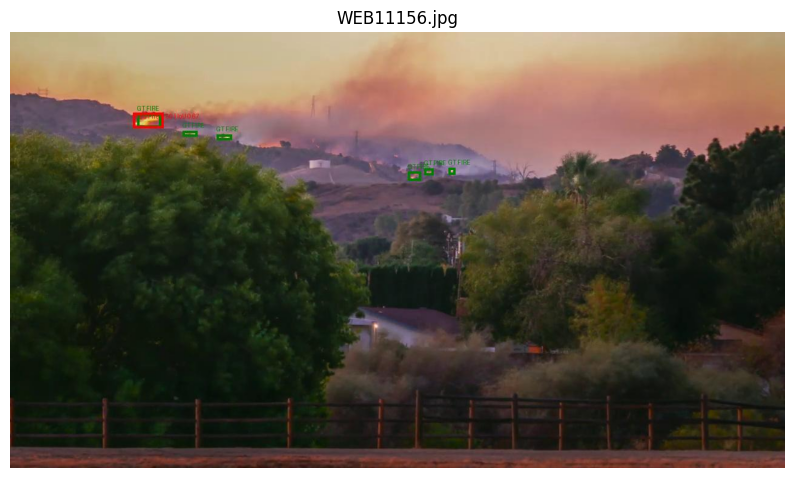

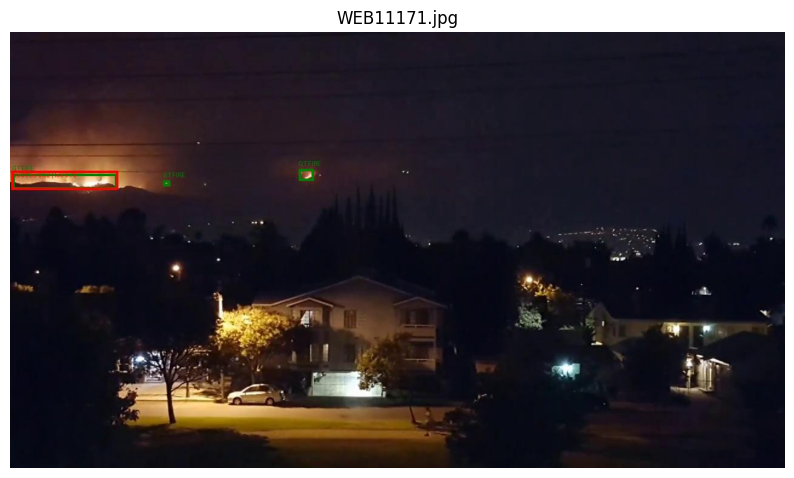

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [5]:
import base64
import json
import threading
import cv2
import numpy as np
import os

from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from IPython.display import display, HTML
from google.colab.output import eval_js
from ultralytics import YOLO

PORT = 8000
DEVICE = "cpu"
CONF = 0.25
IMG_SIZE = 640
MODEL_PATH = "/content/drive/MyDrive/fire_smoke_best.pt"

if not os.path.exists(MODEL_PATH):
    from google.colab import drive
    drive.mount("/content/drive")

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "Model not found: " + MODEL_PATH
    )

model = YOLO(MODEL_PATH)

HTML_PAGE = r"""
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0, maximum-scale=1.0, user-scalable=no">
<title>Fire Detection System</title>

<style>
* {
    box-sizing: border-box;
}

body {
    margin: 0;
    background: #080808;
    color: white;
    font-family: Arial, Helvetica, sans-serif;
    display: flex;
    justify-content: center;
    min-height: 100vh;
}

.container {
    width: 100%;
    max-width: 1000px;
    padding: 15px;
}

.header {
    text-align: center;
    margin-bottom: 15px;
}

.header h1 {
    margin: 0;
    font-size: 24px;
}

.header p {
    margin: 6px 0 0;
    color: #aaa;
    font-size: 14px;
}

.video-container {
    position: relative;
    width: 100%;
    background: black;
    overflow: hidden;
    border-radius: 14px;
}

#video {
    width: 100%;
    height: auto;
    display: block;
    background: black;
}

#overlay {
    position: absolute;
    left: 0;
    top: 0;
    width: 100%;
    height: 100%;
    pointer-events: none;
}

.controls {
    display: flex;
    gap: 10px;
    margin-top: 15px;
}

button {
    flex: 1;
    padding: 14px;
    border: none;
    border-radius: 10px;
    font-size: 17px;
    font-weight: bold;
    cursor: pointer;
}

#startBtn {
    background: #16803c;
    color: white;
}

#stopBtn {
    background: #9b2020;
    color: white;
}

button:disabled {
    opacity: 0.45;
    cursor: not-allowed;
}

#message {
    text-align: center;
    margin-top: 12px;
    min-height: 22px;
    font-size: 15px;
    color: #aaa;
}

#error {
    display: none;
    margin-top: 12px;
    padding: 12px;
    border-radius: 10px;
    background: #401010;
    color: #ffb0b0;
    font-size: 14px;
    word-break: break-word;
}

.fire-alert {
    position: fixed;
    left: 50%;
    top: 20px;
    transform: translateX(-50%);
    z-index: 9999;
    display: none;
    background: #d00000;
    color: white;
    padding: 15px 25px;
    border-radius: 12px;
    font-size: 22px;
    font-weight: bold;
    box-shadow: 0 0 30px rgba(255,0,0,0.7);
}
</style>
</head>

<body>

<div class="container">

<div class="header">
<h1>🔥 Fire Detection System</h1>
<p>Real-time fire monitoring</p>
</div>

<div class="video-container">
<video id="video" autoplay playsinline></video>
<canvas id="overlay"></canvas>
</div>

<div class="controls">
<button id="startBtn">START</button>
<button id="stopBtn" disabled>STOP</button>
</div>

<div id="message">Camera starting...</div>

<div id="error"></div>

</div>

<div id="fireAlert">🔥 FIRE DETECTED 🔥</div>

<script>

const video = document.getElementById("video");
const canvas = document.getElementById("overlay");
const ctx = canvas.getContext("2d");

const startBtn = document.getElementById("startBtn");
const stopBtn = document.getElementById("stopBtn");
const message = document.getElementById("message");
const errorBox = document.getElementById("error");
const fireAlert = document.getElementById("fireAlert");

let stream = null;
let monitoring = false;
let timer = null;
let busy = false;
let apiURL = null;

const captureCanvas = document.createElement("canvas");
const captureCtx = captureCanvas.getContext("2d");

let audioContext = null;
let alarmTimer = null;
let alarmRunning = false;

async function getAPI() {
    try {
        if (
            window.google &&
            google.colab &&
            google.colab.kernel &&
            google.colab.kernel.proxyPort
        ) {
            apiURL = await google.colab.kernel.proxyPort(8000);
        } else {
            apiURL = window.location.origin;
        }

        return true;

    } catch (err) {
        showError("Backend connection error: " + err.message);
        return false;
    }
}

async function startCamera() {
    try {
        stream = await navigator.mediaDevices.getUserMedia({
            video: {
                facingMode: {
                    ideal: "user"
                },
                width: {
                    ideal: 1280
                },
                height: {
                    ideal: 720
                }
            },
            audio: false
        });

        video.srcObject = stream;

        await video.play();

        resizeCanvas();

        message.textContent = "Camera ready — press START";

    } catch (err) {
        showError(
            "Camera error: " +
            err.name +
            " - " +
            err.message
        );
    }
}

function resizeCanvas() {
    if (
        video.videoWidth > 0 &&
        video.videoHeight > 0
    ) {
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
    }
}

function clearOverlay() {
    ctx.clearRect(
        0,
        0,
        canvas.width,
        canvas.height
    );
}

async function initAudio() {
    if (!audioContext) {
        audioContext = new (
            window.AudioContext ||
            window.webkitAudioContext
        )();
    }

    if (audioContext.state === "suspended") {
        await audioContext.resume();
    }
}

async function startMonitoring() {

    if (!stream) {
        await startCamera();
    }

    if (!stream) {
        return;
    }

    if (!apiURL) {
        const connected = await getAPI();

        if (!connected) {
            return;
        }
    }

    try {
        await initAudio();
    } catch (e) {
        console.log(e);
    }

    monitoring = true;
    busy = false;

    startBtn.disabled = true;
    stopBtn.disabled = false;

    message.textContent = "Monitoring started";

    clearOverlay();

    await analyzeFrame();

    timer = setInterval(
        analyzeFrame,
        1000
    );
}

function stopMonitoring() {

    monitoring = false;

    if (timer !== null) {
        clearInterval(timer);
        timer = null;
    }

    busy = false;

    clearOverlay();

    stopAlarm();

    fireAlert.style.display = "none";

    startBtn.disabled = false;
    stopBtn.disabled = true;

    message.textContent = "Monitoring stopped";
}

async function analyzeFrame() {

    if (!monitoring) {
        return;
    }

    if (busy) {
        return;
    }

    if (!apiURL) {
        return;
    }

    if (
        video.videoWidth === 0 ||
        video.videoHeight === 0
    ) {
        return;
    }

    busy = true;

    try {

        resizeCanvas();

        captureCanvas.width = video.videoWidth;
        captureCanvas.height = video.videoHeight;

        captureCtx.drawImage(
            video,
            0,
            0,
            captureCanvas.width,
            captureCanvas.height
        );

        const imageData =
            captureCanvas.toDataURL(
                "image/jpeg",
                0.80
            );

        const response = await fetch(
            apiURL + "/predict",
            {
                method: "POST",
                headers: {
                    "Content-Type": "application/json"
                },
                body: JSON.stringify({
                    image: imageData
                })
            }
        );

        const result = await response.json();

        if (!response.ok) {
            throw new Error(
                result.error ||
                "Server returned " +
                response.status
            );
        }

        if (!monitoring) {
            return;
        }

        drawDetections(
            result.boxes || []
        );

        if (result.fire === true) {

            startAlarm();

            fireAlert.style.display = "block";

            message.textContent =
                "🔥 FIRE DETECTED";

        } else {

            stopAlarm();

            fireAlert.style.display = "none";

            message.textContent =
                "Monitoring...";

        }

    } catch (err) {

        console.error(err);

        showError(
            "Detection error: " +
            err.message
        );

    } finally {

        busy = false;
    }
}

function drawDetections(boxes) {

    clearOverlay();

    for (const box of boxes) {

        const x1 = box.x1;
        const y1 = box.y1;
        const x2 = box.x2;
        const y2 = box.y2;

        const confidence =
            box.confidence;

        ctx.lineWidth =
            Math.max(
                3,
                canvas.width / 400
            );

        ctx.strokeStyle = "#ff0000";

        ctx.strokeRect(
            x1,
            y1,
            x2 - x1,
            y2 - y1
        );

        const fontSize =
            Math.max(
                18,
                canvas.width / 45
            );

        ctx.font =
            "bold " +
            fontSize +
            "px Arial";

        const label =
            "FIRE " +
            (confidence * 100).toFixed(1) +
            "%";

        const textWidth =
            ctx.measureText(label).width;

        const labelHeight =
            fontSize + 12;

        const labelX = x1;

        const labelY =
            Math.max(
                labelHeight,
                y1
            );

        ctx.fillStyle = "#ff0000";

        ctx.fillRect(
            labelX,
            labelY - labelHeight,
            textWidth + 14,
            labelHeight
        );

        ctx.fillStyle = "#ffffff";

        ctx.fillText(
            label,
            labelX + 7,
            labelY - 7
        );
    }
}

function beep() {

    if (!audioContext) {
        return;
    }

    const oscillator =
        audioContext.createOscillator();

    const gain =
        audioContext.createGain();

    oscillator.type = "square";

    oscillator.frequency.value = 950;

    gain.gain.setValueAtTime(
        0,
        audioContext.currentTime
    );

    gain.gain.linearRampToValueAtTime(
        0.25,
        audioContext.currentTime + 0.02
    );

    gain.gain.linearRampToValueAtTime(
        0,
        audioContext.currentTime + 0.18
    );

    oscillator.connect(gain);

    gain.connect(
        audioContext.destination
    );

    oscillator.start();

    oscillator.stop(
        audioContext.currentTime + 0.20
    );
}

function startAlarm() {

    if (alarmRunning) {
        return;
    }

    alarmRunning = true;

    beep();

    alarmTimer =
        setInterval(
            beep,
            250
        );
}

function stopAlarm() {

    alarmRunning = false;

    if (alarmTimer !== null) {

        clearInterval(
            alarmTimer
        );

        alarmTimer = null;
    }
}

function showError(text) {

    errorBox.style.display = "block";

    errorBox.textContent = text;
}

startBtn.addEventListener(
    "click",
    startMonitoring
);

stopBtn.addEventListener(
    "click",
    stopMonitoring
);

(async function() {

    await getAPI();

    await startCamera();

})();

</script>

</body>
</html>
"""


class FireDetectionHandler(BaseHTTPRequestHandler):

    def send_cors(self):

        self.send_header(
            "Access-Control-Allow-Origin",
            "*"
        )

        self.send_header(
            "Access-Control-Allow-Headers",
            "Content-Type"
        )

        self.send_header(
            "Access-Control-Allow-Methods",
            "GET, POST, OPTIONS"
        )

    def do_GET(self):

        if self.path in ["/", "/app"]:

            content = HTML_PAGE.encode("utf-8")

            self.send_response(200)

            self.send_header(
                "Content-Type",
                "text/html; charset=utf-8"
            )

            self.send_header(
                "Content-Length",
                str(len(content))
            )

            self.send_cors()

            self.end_headers()

            self.wfile.write(content)

        else:

            self.send_response(404)

            self.send_cors()

            self.end_headers()

    def do_OPTIONS(self):

        self.send_response(204)

        self.send_cors()

        self.end_headers()

    def do_POST(self):

        if self.path != "/predict":

            self.send_response(404)

            self.send_cors()

            self.end_headers()

            return

        try:

            content_length = int(
                self.headers.get(
                    "Content-Length",
                    0
                )
            )

            body = self.rfile.read(
                content_length
            )

            data = json.loads(
                body.decode("utf-8")
            )

            image_data = data["image"]

            encoded = image_data.split(
                ",",
                1
            )[1]

            image_bytes = base64.b64decode(
                encoded
            )

            image_array = np.frombuffer(
                image_bytes,
                dtype=np.uint8
            )

            frame = cv2.imdecode(
                image_array,
                cv2.IMREAD_COLOR
            )

            if frame is None:
                raise ValueError(
                    "Could not decode image"
                )

            results = model.predict(
                source=frame,
                imgsz=IMG_SIZE,
                conf=CONF,
                device=DEVICE,
                verbose=False
            )

            result = results[0]

            boxes = []

            fire_found = False

            if result.boxes is not None:

                xyxy = (
                    result.boxes.xyxy
                    .cpu()
                    .numpy()
                )

                confidences = (
                    result.boxes.conf
                    .cpu()
                    .numpy()
                )

                classes = (
                    result.boxes.cls
                    .cpu()
                    .numpy()
                )

                for i in range(len(xyxy)):

                    class_id = int(
                        classes[i]
                    )

                    confidence = float(
                        confidences[i]
                    )

                    if class_id != 1:
                        continue

                    x1, y1, x2, y2 = xyxy[i]

                    fire_found = True

                    boxes.append({
                        "x1": float(x1),
                        "y1": float(y1),
                        "x2": float(x2),
                        "y2": float(y2),
                        "confidence": confidence,
                        "class_id": class_id
                    })

            response = {
                "fire": fire_found,
                "boxes": boxes
            }

            response_bytes = json.dumps(
                response
            ).encode("utf-8")

            self.send_response(200)

            self.send_header(
                "Content-Type",
                "application/json"
            )

            self.send_header(
                "Content-Length",
                str(len(response_bytes))
            )

            self.send_cors()

            self.end_headers()

            self.wfile.write(
                response_bytes
            )

        except Exception as e:

            response = {
                "fire": False,
                "boxes": [],
                "error": str(e)
            }

            response_bytes = json.dumps(
                response
            ).encode("utf-8")

            self.send_response(500)

            self.send_header(
                "Content-Type",
                "application/json"
            )

            self.send_header(
                "Content-Length",
                str(len(response_bytes))
            )

            self.send_cors()

            self.end_headers()

            self.wfile.write(
                response_bytes
            )

    def log_message(self, format, *args):
        return


try:
    server.shutdown()
    server.server_close()
except:
    pass

server = ThreadingHTTPServer(
    ("0.0.0.0", PORT),
    FireDetectionHandler
)

thread = threading.Thread(
    target=server.serve_forever,
    daemon=True
)

thread.start()

url = eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

display(
    HTML(
        f"""
        <a href="{url}" target="_blank"
           style="
           display:block;
           text-align:center;
           padding:20px;
           background:#16803c;
           color:white;
           font-size:20px;
           font-weight:bold;
           text-decoration:none;
           border-radius:12px;">
           🔥 Open Fire Detection System
        </a>
        """
    )
)

print("🔥 Fire Detection System Started")
print("Model:", MODEL_PATH)
print("Confidence:", CONF)
print("Image Size:", IMG_SIZE)
print("Phone URL:", url)

🔥 Fire Detection System Started
Model: /content/drive/MyDrive/fire_smoke_best.pt
Confidence: 0.25
Image Size: 640
Phone URL: https://8000-m-s-use1d5-2ztcvz0gn0hfi-d.us-east1.prod.r.colab.dev
